<a href="https://colab.research.google.com/github/Szymon-Jablonski/ml-speech-denoiser/blob/main/denoiser_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Speech denoiser with classic Convolutional Neural Network (CNN) approach

In [17]:
from google.colab import drive
drive.mount('/content/drive')

!tar -xf /content/drive/MyDrive/Denoiser/DenoiserData.tar -C /content/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
!pip install torchaudio soundfile matplotlib

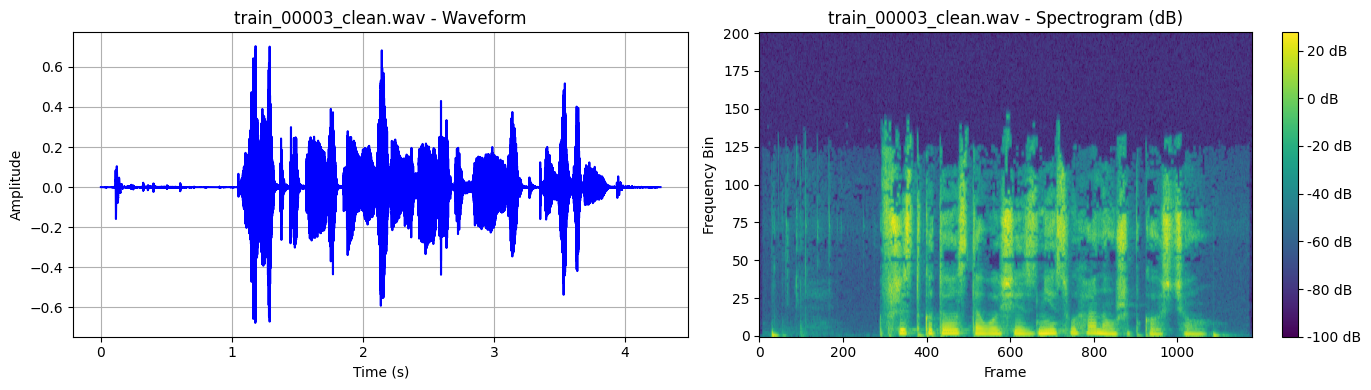

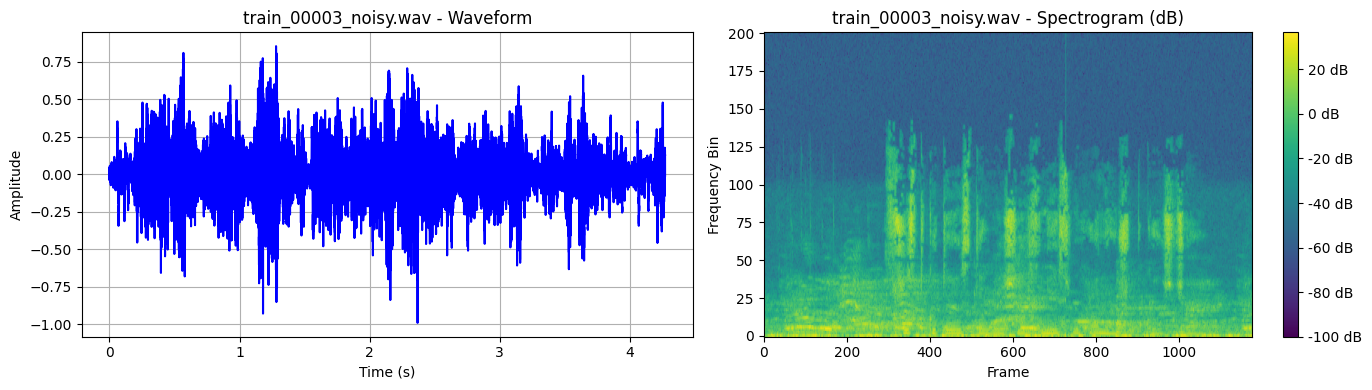

In [22]:
import torch
import torchaudio
import torchaudio.transforms as T
import matplotlib.pyplot as plt

def load_audio(file_path):
    """Loads an audio file directly without modifying its sample rate or channels."""
    waveform, sr = torchaudio.load(file_path)
    return waveform, sr

def plot_waveform_and_spectrogram(waveform, sr, title="Audio Signal"):
    """Plots the waveform and its corresponding spectrogram side by side."""
    # Compute spectrogram
    spec_transform = T.Spectrogram(n_fft=400, hop_length=160)
    spectrogram = spec_transform(waveform)

    # Convert to log scale (dB)
    log_spectrogram = torchaudio.transforms.AmplitudeToDB()(spectrogram)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Plot Waveform
    time_axis = torch.arange(0, waveform.size(1)) / sr
    axes[0].plot(time_axis.numpy(), waveform[0].numpy(), color='b')
    axes[0].set_title(f"{title} - Waveform")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(True)

    # Plot Spectrogram
    im = axes[1].imshow(log_spectrogram[0].numpy(), origin="lower", aspect="auto", cmap="viridis")
    axes[1].set_title(f"{title} - Spectrogram (dB)")
    axes[1].set_xlabel("Frame")
    axes[1].set_ylabel("Frequency Bin")
    fig.colorbar(im, ax=axes[1], format="%1.0f dB")

    plt.tight_layout()
    plt.show()

# Generate spectrograms from train dataset

clean_waveform, clean_sr = load_audio('/content/DenoiserData/Train/train_00003_clean.wav')
plot_waveform_and_spectrogram(clean_waveform, clean_sr, title="train_00003_clean.wav")

noisy_waveform, noisy_sr = load_audio('/content/DenoiserData/Train/train_00003_noisy.wav')
plot_waveform_and_spectrogram(noisy_waveform, noisy_sr, title="train_00003_noisy.wav")

